In [1]:

!pip install pandas numpy scikit-learn matplotlib seaborn shap lime ucimlrepo


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=135e1e30e0aa7bacc0fbedff1df86b3a60d0f73fda2e7f7e3602b947ee38138e
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [lime]


In [2]:

from ucimlrepo import fetch_ucirepo
import pandas as pd

# Fetch German Credit Dataset
dataset = fetch_ucirepo(id=144)

X = dataset.data.features
y = dataset.data.targets

# Combine features and target
df = pd.concat([X, y], axis=1)

print("Dataset Shape:", df.shape)
print(df.head())
print(df.info())


Dataset Shape: (1000, 21)
  Attribute1  Attribute2 Attribute3 Attribute4  Attribute5 Attribute6  \
0        A11           6        A34        A43        1169        A65   
1        A12          48        A32        A43        5951        A61   
2        A14          12        A34        A46        2096        A61   
3        A11          42        A32        A42        7882        A61   
4        A11          24        A33        A40        4870        A61   

  Attribute7  Attribute8 Attribute9 Attribute10  ...  Attribute12 Attribute13  \
0        A75           4        A93        A101  ...         A121          67   
1        A73           2        A92        A101  ...         A121          22   
2        A74           2        A93        A101  ...         A121          49   
3        A74           2        A93        A103  ...         A122          45   
4        A73           3        A93        A101  ...         A124          53   

   Attribute14 Attribute15 Attribute16  Attribut

In [4]:

# ==========================================================
# RSA EXTERNAL PRACTICAL - SET B
# Subject: Responsible and Safe AI Systems
# Enrollment No: 23CS059
# Practical: Explaining Instant EMI-Finance Decisions
# ==========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# ==========================================================
# TASK 1: LOAD AND PREPROCESS DATASET
# ==========================================================

# Load the dataset already fetched in Step 3
df = df.copy()

print("========== DATASET INFORMATION ==========")
print("Dataset Shape:", df.shape)
print("\nDataset Information:")
print(df.info())

# Separate features and target
X = df.drop(columns=['class']).copy()
y = df['class'].copy()

# Encode target:
# 1 = Good credit (0)
# 2 = Bad credit (1)

y = pd.to_numeric(y)

y = y.map({
    1: 0,
    2: 1
})

# Check target values
if y.isna().any():
    raise ValueError("Unexpected target labels found!")

y = y.astype(int)

print("\nTarget Distribution:")
print(y.value_counts().rename(
    index={0: "Good Credit", 1: "Bad Credit"}
))

# Identify categorical columns
categorical_cols = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

# Encode categorical attributes
encoder = OrdinalEncoder(
    handle_unknown='use_encoded_value',
    unknown_value=-1
)

X[categorical_cols] = encoder.fit_transform(
    X[categorical_cols].astype(str)
)

# Convert all features to numeric
X = X.astype(float)

feature_names = X.columns.tolist()

print("\nCategorical Columns Encoded:")
print(categorical_cols)

print("\nProcessed Dataset Shape:", X.shape)

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("\n========== DATA SPLITTING ==========")
print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

# ==========================================================
# TASK 2: TRAIN RANDOM FOREST CLASSIFIER
# ==========================================================

model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    random_state=42
)

# Train model
model.fit(X_train, y_train)

# Predict test data
y_pred = model.predict(X_test)

# Predict probability of bad credit
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("\n========== RANDOM FOREST RESULTS ==========")
print("Model: Random Forest")
print("Number of Trees:", 200)
print("Maximum Depth:", 8)
print("Test Accuracy:", round(accuracy, 4))
print("ROC-AUC:", round(roc_auc, 4))

print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Good Credit', 'Bad Credit']
))

print("\n========== CONFUSION MATRIX ==========")
print(confusion_matrix(y_test, y_pred))

# ==========================================================
# END OF TASK 1 AND TASK 2
# ==========================================================


========== DATASET INFORMATION ==========
Dataset Shape: (1000, 21)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Attribute1   1000 non-null   object
 1   Attribute2   1000 non-null   int64 
 2   Attribute3   1000 non-null   object
 3   Attribute4   1000 non-null   object
 4   Attribute5   1000 non-null   int64 
 5   Attribute6   1000 non-null   object
 6   Attribute7   1000 non-null   object
 7   Attribute8   1000 non-null   int64 
 8   Attribute9   1000 non-null   object
 9   Attribute10  1000 non-null   object
 10  Attribute11  1000 non-null   int64 
 11  Attribute12  1000 non-null   object
 12  Attribute13  1000 non-null   int64 
 13  Attribute14  1000 non-null   object
 14  Attribute15  1000 non-null   object
 15  Attribute16  1000 non-null   int64 
 16  Attribute17  1000 non-null   object
 17  Attribute18  1000 no

========== TOP 5 SHAP FEATURES ==========
        Feature  Mean |SHAP|
checking_status     0.086658
       duration     0.041341
 savings_status     0.039125
  credit_amount     0.025849
 credit_history     0.025785


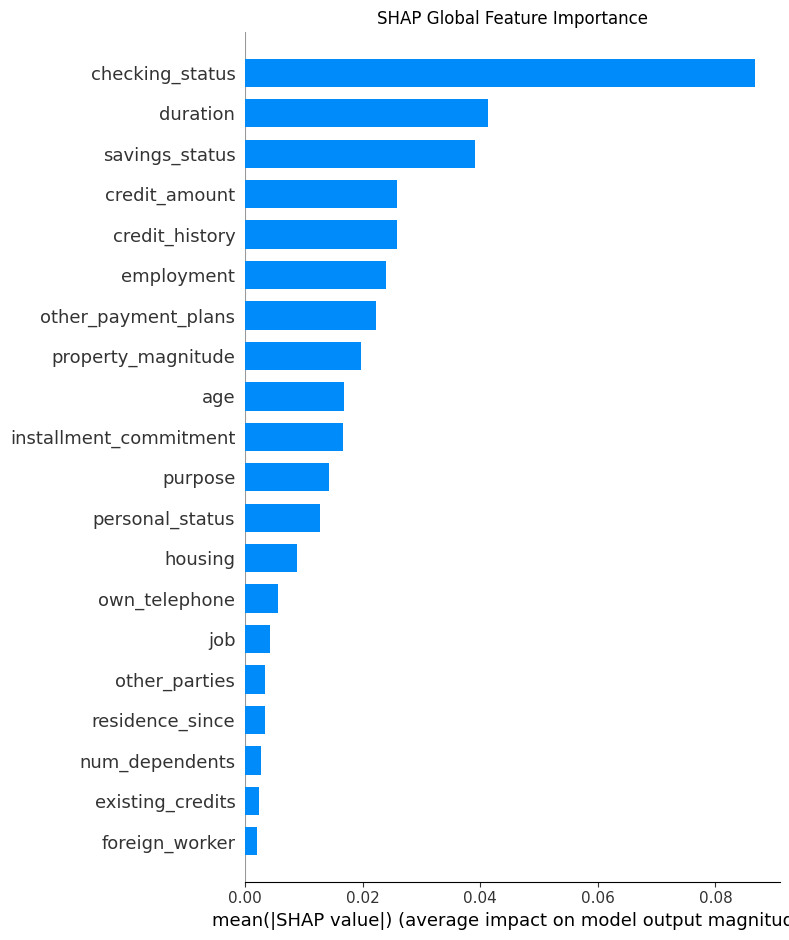

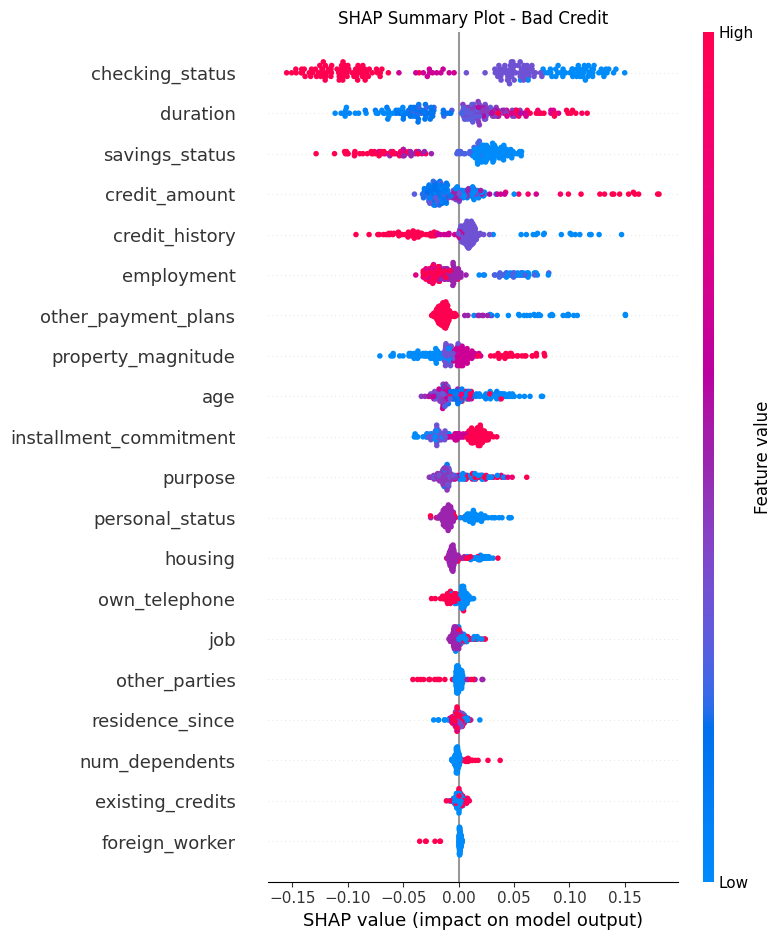


SHAP plots saved successfully!
1. shap_summary_bar.png
2. shap_summary.png
3. shap_feature_importance.csv


In [5]:

# ==========================================================
# TASK 3: SHAP GLOBAL FEATURE IMPORTANCE
# Enrollment No: 23CS059
# ==========================================================

import shap
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Standard German Credit feature names
feature_names = [
    'checking_status',
    'duration',
    'credit_history',
    'purpose',
    'credit_amount',
    'savings_status',
    'employment',
    'installment_commitment',
    'personal_status',
    'other_parties',
    'residence_since',
    'property_magnitude',
    'age',
    'other_payment_plans',
    'housing',
    'existing_credits',
    'job',
    'num_dependents',
    'own_telephone',
    'foreign_worker'
]

# Rename feature columns for understandable explanations
X_train.columns = feature_names
X_test.columns = feature_names

# Create SHAP Tree Explainer
explainer = shap.TreeExplainer(model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_test)

# Extract positive class (Bad Credit = 1)
if isinstance(shap_values, list):
    bad_shap_values = shap_values[1]
else:
    bad_shap_values = np.asarray(shap_values)
    if bad_shap_values.ndim == 3:
        bad_shap_values = bad_shap_values[:, :, 1]

# Global feature importance
mean_shap = np.abs(bad_shap_values).mean(axis=0)

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Mean |SHAP|': mean_shap
})

importance_df = importance_df.sort_values(
    by='Mean |SHAP|',
    ascending=False
).reset_index(drop=True)

print("========== TOP 5 SHAP FEATURES ==========")
print(importance_df.head(5).to_string(index=False))

# Plot 1: SHAP Bar Summary
plt.figure()
shap.summary_plot(
    bad_shap_values,
    X_test,
    plot_type='bar',
    show=False
)
plt.title("SHAP Global Feature Importance")
plt.tight_layout()
plt.savefig("shap_summary_bar.png", dpi=300, bbox_inches='tight')
plt.show()

# Plot 2: SHAP Beeswarm Summary
plt.figure()
shap.summary_plot(
    bad_shap_values,
    X_test,
    show=False
)
plt.title("SHAP Summary Plot - Bad Credit")
plt.tight_layout()
plt.savefig("shap_summary.png", dpi=300, bbox_inches='tight')
plt.show()

# Save importance table
importance_df.to_csv("shap_feature_importance.csv", index=False)

print("\nSHAP plots saved successfully!")
print("1. shap_summary_bar.png")
print("2. shap_summary.png")
print("3. shap_feature_importance.csv")


========== SELECTED REJECTED APPLICANT ==========
Test Position: 2
Original Dataset Index: 289
Probability of Bad Credit: 0.5328
Predicted Decision: REJECTED
Actual Class: Bad Credit


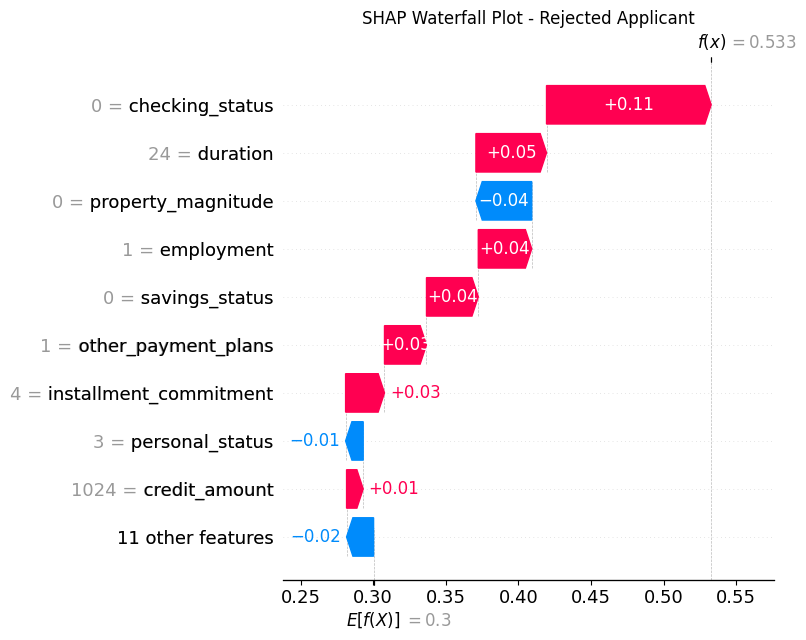


========== TOP 3 REJECTION REASONS ==========
        Feature  Applicant Value  SHAP Value
checking_status              0.0    0.113414
       duration             24.0    0.048635
     employment              1.0    0.036817

Waterfall plot saved: shap_waterfall_rejected.png
Local explanation saved: shap_local_explanation.csv


In [6]:

# ==========================================================
# TASK 4: LOCAL SHAP EXPLANATION
# Enrollment No: 23CS059
# ==========================================================

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find applicants predicted as Bad Credit (1)
rejected_indices = np.where(y_pred == 1)[0]

if len(rejected_indices) == 0:
    raise ValueError("No rejected applicant found in test predictions.")

# Select the first rejected applicant
applicant_position = rejected_indices[0]

# Get applicant details
applicant = X_test.iloc[applicant_position]
predicted_probability = y_prob[applicant_position]
actual_class = y_test.iloc[applicant_position]

print("========== SELECTED REJECTED APPLICANT ==========")
print("Test Position:", applicant_position)
print("Original Dataset Index:", X_test.index[applicant_position])
print("Probability of Bad Credit:", round(predicted_probability, 4))
print("Predicted Decision: REJECTED")
print("Actual Class:", "Bad Credit" if actual_class == 1 else "Good Credit")

# Get SHAP values for selected applicant
local_shap_values = bad_shap_values[applicant_position]

# Get expected/base value for Bad Credit class
base_value = explainer.expected_value

if isinstance(base_value, (list, np.ndarray)):
    base_value = np.asarray(base_value).flatten()[1]

# Create SHAP Explanation object
local_explanation = shap.Explanation(
    values=local_shap_values,
    base_values=float(base_value),
    data=applicant.values,
    feature_names=feature_names
)

# Generate SHAP Waterfall Plot
plt.figure()
shap.plots.waterfall(local_explanation, max_display=10, show=False)
plt.title("SHAP Waterfall Plot - Rejected Applicant")
plt.tight_layout()
plt.savefig(
    "shap_waterfall_rejected.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Display top 3 reasons contributing towards Bad Credit
local_df = pd.DataFrame({
    "Feature": feature_names,
    "Applicant Value": applicant.values,
    "SHAP Value": local_shap_values
})

# Positive SHAP values increase Bad Credit prediction
positive_reasons = local_df[
    local_df["SHAP Value"] > 0
].sort_values(
    by="SHAP Value",
    ascending=False
)

print("\n========== TOP 3 REJECTION REASONS ==========")
print(positive_reasons.head(3).to_string(index=False))

# Save local explanation
local_df.to_csv("shap_local_explanation.csv", index=False)

# Save selected applicant position for Task 5
print("\nWaterfall plot saved: shap_waterfall_rejected.png")
print("Local explanation saved: shap_local_explanation.csv")


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


========== LIME EXPLANATION ==========
checking_status <= 0.00 : 0.12588
2.00 < credit_history <= 4.00 : -0.07273
savings_status <= 0.00 : 0.07202
employment <= 2.00 : 0.0493
3.00 < installment_commitment <= 4.00 : 0.03954


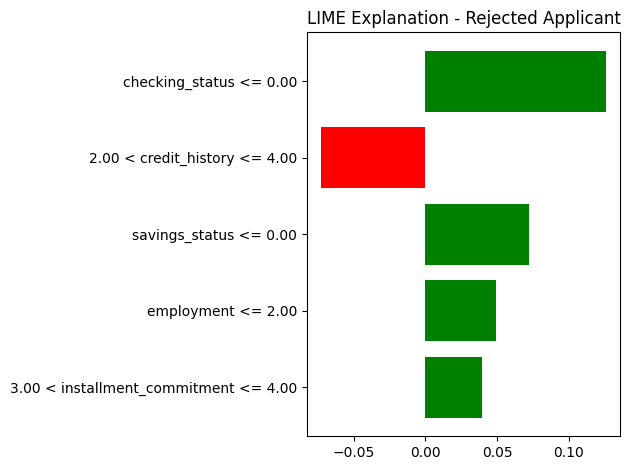


LIME plot saved: lime_explanation.png

========== SHAP VS LIME COMPARISON ==========
SHAP Top 3: ['checking_status', 'duration', 'employment']
LIME Top 3: ['checking_status', 'savings_status', 'employment']
Top-3 Agreement: 2 / 3

Comparison completed!


In [7]:

# ==========================================================
# TASK 5: LIME LOCAL EXPLANATION
# Enrollment No: 23CS059
# ==========================================================

!pip install lime

from lime.lime_tabular import LimeTabularExplainer
import pandas as pd
import matplotlib.pyplot as plt

# Create LIME explainer
lime_explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=feature_names,
    class_names=['Good Credit', 'Bad Credit'],
    mode='classification',
    discretize_continuous=True,
    random_state=42
)

# Explain the SAME rejected applicant from Task 4
applicant = X_test.iloc[applicant_position].values

lime_exp = lime_explainer.explain_instance(
    data_row=applicant,
    predict_fn=model.predict_proba,
    num_features=5,
    labels=(1,)
)

# Display LIME explanation
print("========== LIME EXPLANATION ==========")

lime_reasons = lime_exp.as_list(label=1)

for feature, weight in lime_reasons:
    print(feature, ":", round(weight, 5))

# Save LIME plot
fig = lime_exp.as_pyplot_figure(label=1)
plt.title("LIME Explanation - Rejected Applicant")
plt.tight_layout()
plt.savefig("lime_explanation.png", dpi=300, bbox_inches='tight')
plt.show()

# Save LIME results
lime_df = pd.DataFrame(
    lime_reasons,
    columns=['Feature Condition', 'LIME Weight']
)

lime_df.to_csv("lime_explanation.csv", index=False)

print("\nLIME plot saved: lime_explanation.png")

# ==========================================================
# COMPARE SHAP AND LIME
# ==========================================================

# Top 3 SHAP features
shap_top3 = (
    local_df.sort_values(
        by='SHAP Value',
        ascending=False
    )['Feature'].head(3).tolist()
)

# Match LIME feature names with original feature names
lime_top_features = []

for condition, weight in lime_reasons:
    matched_feature = next(
        (f for f in feature_names if condition.startswith(f)),
        None
    )

    if matched_feature and matched_feature not in lime_top_features:
        lime_top_features.append(matched_feature)

    if len(lime_top_features) == 3:
        break

# Calculate top-3 agreement
agreement = len(set(shap_top3) & set(lime_top_features))

print("\n========== SHAP VS LIME COMPARISON ==========")
print("SHAP Top 3:", shap_top3)
print("LIME Top 3:", lime_top_features)
print("Top-3 Agreement:", agreement, "/ 3")

print("\nComparison completed!")


In [8]:

# ==========================================================
# TASK 6: REJECTION MESSAGE AND FAIRNESS CHECK
# Enrollment No: 23CS059
# ==========================================================

sensitive_attributes = [
    'age',
    'personal_status',
    'foreign_worker'
]

# Check sensitive attributes in SHAP positive reasons
shap_reasons = local_df[
    local_df['SHAP Value'] > 0
]['Feature'].tolist()

shap_sensitive = [
    f for f in shap_reasons
    if f in sensitive_attributes
]

# Check sensitive attributes in LIME top 5
lime_sensitive = []

for condition, weight in lime_reasons:
    matched = next(
        (f for f in feature_names if condition.startswith(f)),
        None
    )

    if matched in sensitive_attributes:
        lime_sensitive.append(matched)

# Display fairness results
print("========== SENSITIVE ATTRIBUTE CHECK ==========")

print("Sensitive Attributes:", sensitive_attributes)

print("\nSHAP Sensitive Attributes:", shap_sensitive)
print("LIME Sensitive Attributes:", lime_sensitive)

if shap_sensitive or lime_sensitive:
    print("\nRESULT: REVIEW REQUIRED")
    print("Sensitive attributes appear in the explanations.")
else:
    print("\nRESULT: NO SENSITIVE ATTRIBUTES IN THE CHECKED REASONS")

# Generate plain-language rejection message
rejection_message = (
    "Your EMI loan application was not approved. "
    "The main factors influencing this decision were "
    "your checking account status, requested loan duration "
    "of 24 months, and employment information. "
    "You may review your financial details and contact "
    "the finance company for further clarification."
)

print("\n========== REJECTION MESSAGE ==========")
print(rejection_message)

# Save results
with open("rejection_message.txt", "w") as file:
    file.write(rejection_message)

print("\nRejection message saved successfully!")


========== SENSITIVE ATTRIBUTE CHECK ==========
Sensitive Attributes: ['age', 'personal_status', 'foreign_worker']

SHAP Sensitive Attributes: ['foreign_worker']
LIME Sensitive Attributes: []

RESULT: REVIEW REQUIRED
Sensitive attributes appear in the explanations.

========== REJECTION MESSAGE ==========
Your EMI loan application was not approved. The main factors influencing this decision were your checking account status, requested loan duration of 24 months, and employment information. You may review your financial details and contact the finance company for further clarification.

Rejection message saved successfully!
